This notebook runs uses naima's MCMC but from a model constructed with f2py functions.

The notebook also has a twin model constructed with naima functions (commented out).

The data is created from a previous run of "Example_sync_code".

It runs pretty slow. To make it faster, deactive SSC in model_f2py.

In [1]:
import naima
from naima.models import ExponentialCutoffPowerLaw
import astropy.units as u
from astropy.constants import c
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
import jet

### Create observation file

In [3]:
# SYNC DATA

sed_compare_sync = np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/radsyn.dat")
# sed_compare[:,0] has the photon energies [eV]
# sed_compare[:,1] has the luminosities per unit of energy [erg/s/erg]
desample=150
# Convert sed_compare[:,0] to units of erg or eV and reduce sampling:
sed_compare_energy_sync_eV = sed_compare_sync[::desample,0]*u.eV
sed_compare_energy_sync_erg = sed_compare_energy_sync_eV.to( u.erg)
# Convert sed_compare[:,1] to units of 1/erg/s/cm^2
sed_compare_sync = sed_compare_sync[::desample,1] / ( (u.second * 4*np.pi*(1*u.kpc)**2) * sed_compare_energy_sync_erg )
sed_compare_sync = sed_compare_sync.to( 1/ u.s / u.cm / u.cm / u.erg)
# Define flux errors:
#sed_compare_sync_err = sed_compare_sync * 0.1 * (1/np.random.randint(1,10,len(sed_compare_sync)))

In [4]:
# SSC DATA

sed_compare_ssc = np.loadtxt("/home/fglsma/Dropbox/Trabajo/Investigacion/eht_garra/ExtendedJet/Example_sync_code/radssc.dat")
# sed_compare[:,0] has the photon energies [eV]
# sed_compare[:,1] has the luminosities per unit of energy [erg/s/erg]
desample=40
# Convert sed_compare[:,0] to units of erg or eV and reduce sampling:
sed_compare_energy_ssc_eV = sed_compare_ssc[::desample,0]*u.eV
sed_compare_energy_ssc_erg = sed_compare_energy_ssc_eV.to( u.erg)
# Convert sed_compare[:,1] to units of 1/erg/s/cm^2
sed_compare_ssc = sed_compare_ssc[::desample,1] / ( (u.second * 4*np.pi*(1*u.kpc)**2) * sed_compare_energy_ssc_erg )
sed_compare_ssc = sed_compare_ssc.to( 1/ u.s / u.cm / u.cm / u.erg)

In [5]:
# JOINT DATA

# Join the energies:
sed_compare_energy_eV = np.concatenate(( sed_compare_energy_sync_eV[:6]/u.eV, sed_compare_energy_ssc_eV[-3:-1]/u.eV))
# Sort them:
sed_compare_energy_eV.sort()
sed_compare_energy_eV = sed_compare_energy_eV * u.eV
sed_compare = np.zeros((len(sed_compare_energy_eV)))# / u.s / u.cm / u.cm / u.erg
# Interpolate and sum the fluxes:
for it in range( len(sed_compare_energy_eV)):
    sync_temp = 0
    ssc_temp = 0
    if sed_compare_energy_eV[it] >= sed_compare_energy_sync_eV[0] and sed_compare_energy_eV[it] <= sed_compare_energy_sync_eV[-1]:
        sync_temp = np.interp( sed_compare_energy_eV[it]/u.eV, sed_compare_energy_sync_eV/u.eV, sed_compare_sync / (1/ u.s / u.cm / u.cm / u.erg))
    if sed_compare_energy_eV[it] >= sed_compare_energy_ssc_eV[0] and sed_compare_energy_eV[it] <= sed_compare_energy_ssc_eV[-1]:
        ssc_temp = np.interp( sed_compare_energy_eV[it]/u.eV, sed_compare_energy_ssc_eV/u.eV, sed_compare_ssc/ (1/ u.s / u.cm / u.cm / u.erg))
        print(it, ssc_temp)
    sed_compare[it] = (sync_temp + ssc_temp)
sed_compare =  sed_compare / u.s / u.cm / u.cm / u.erg

3 84665.77487116026
4 122.66276707187761
5 0.09465279733726228
6 7.242200519969093e-08
7 1.730939263603651e-11


In [6]:
# DEFINE ERRORS

sed_compare_energy_eV_high_err = sed_compare_energy_eV + sed_compare_energy_eV * (0.1/np.random.randint(1,10,len(sed_compare_energy_eV)))
sed_compare_energy_eV_low_err = sed_compare_energy_eV - sed_compare_energy_eV  * (0.1/np.random.randint(1,10,len(sed_compare_energy_eV)))
sed_compare_energy_erg = sed_compare_energy_eV.to( u.erg)
# Define flux errors:
sed_compare_err = sed_compare * 0.1 * (1/np.random.randint(1,10,len(sed_compare)))

<ErrorbarContainer object of 3 artists>

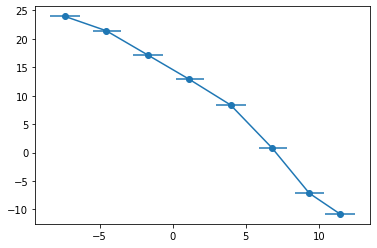

In [7]:
# Plot:
plt.scatter( np.log10(sed_compare_energy_eV/u.eV), \
            np.log10( sed_compare * u.cm * u.cm * u.second * (u.erg )))
yerr= sed_compare_err  / sed_compare
xerr = [sed_compare_energy_eV_low_err, \
               sed_compare_energy_eV_high_err]
xerr = np.asarray( xerr)
xerr[0,:] = xerr[0,:] / sed_compare_energy_eV
xerr[1,:] = xerr[1,:] / sed_compare_energy_eV

plt.errorbar( np.log10(sed_compare_energy_eV/u.eV), \
             np.log10( sed_compare * u.cm * u.cm * u.second * (u.erg )), \
             yerr=yerr, \
             xerr=xerr)
#plt.scatter( np.log10(sed_compare_energy_eV/u.eV), \
#            np.log10( S* u.cm * u.cm * u.second *u.erg))

In [8]:
if os.path.exists("data_sum.ecsv"):
    os.remove("data_sum.ecsv")
f = open("data_sum.ecsv", "a")
f.write("# %ECSV 0.9\n \
# ---\n \
# datatype:\n \
# - {name: energy, unit: eV, datatype: float64}\n \
# - {name: energy_edge_lo, unit: eV, datatype: float64}\n \
# - {name: energy_edge_hi, unit: eV, datatype: float64}\n \
# - {name: flux, unit: 1 / (cm2 s erg), datatype: float64}\n \
# - {name: flux_error, unit: 1 / (cm2 s erg), datatype: float64}\n \
# - {name: ul, unit: '', datatype: int64}\n \
# meta: !!omap\n \
# - comments: [none]\n \
# - keywords: !!omap\n \
#   - cl: {value: 0.95}\n \
energy energy_edge_lo energy_edge_hi flux flux_error ul\n")
for it in range(len(sed_compare_energy_eV)):
        f.write( str(sed_compare_energy_eV[it]/u.eV) + ' ' + \
                str(sed_compare_energy_eV_low_err[it]/u.eV) + ' ' + \
                str(sed_compare_energy_eV_high_err[it]/u.eV) + ' ' + \
                str(sed_compare[it] * u.cm * u.cm * u.second * (u.erg )) + ' ' + \
                str(sed_compare_err[it] * u.cm * u.cm * u.second * (u.erg ) ) + ' ' + \
                str(0) + "\n")     
f.close()

### Read the data

In [9]:
from astropy.io import ascii
#data = ascii.read('syn_data.txt')
data = ascii.read('data_sum.ecsv')

### Define the model (naima version)

In [12]:
"""
from naima.models import ExponentialCutoffPowerLaw, InverseCompton
import astropy.units as u

def model_naima(pars, data):
    # Original model:
    #amplitude = pars[0] / u.eV
    #alpha = pars[1]
    #e_cutoff = (10**pars[2]) * u.TeV
    #ECPL = ExponentialCutoffPowerLaw(amplitude, 10*u.TeV, alpha, e_cutoff)
    #IC = InverseCompton(ECPL, seed_photon_fields=['CMB',
    #                    ['FIR', 26.5 * u.K, 0.415 * u.eV / u.cm**3]])

    e_0=1*u.eV
    e_break=1E100*u.eV
    alpha_1 = 2
    amplitude = 1.7690615972392788E+043*u.erg/u.eV*u.Unit('1/eV') # Taken from stand-alone code 
    alpha_2=0
    e_cutoff= 1.E13*u.eV #(10**pars[2]) * u.TeV #1.E13*u.eV
    beta=1
    
    Q = naima.models.ExponentialCutoffBrokenPowerLaw( amplitude=amplitude, \
                                                 e_0=e_0, \
                                                 e_break=e_break, \
                                                 alpha_1=alpha_1, \
                                                 alpha_2 = alpha_2, \
                                                 e_cutoff=e_cutoff, \
                                                 beta=1)
    
    # Get syn sed
    B = pars[0]*u.G #1E-2*u.G
    distance = 1*u.kpc
    Eemin=1e8*u.eV
    SYN = naima.models.Synchrotron(Q, B=B, Eemin=Eemin)    
    
    Lsy = SYN.flux(data, distance=0*u.cm)
    R = 0.01 *  (1*u.pc).to(u.cm)
    c = 2.99792458e10 * u.cm / u.second
    phn_sy = Lsy / (4 * np.pi * R**2 * c) * 2.24 # This is the specific density of photons
    IC = naima.models.InverseCompton(Q, seed_photon_fields=[['SSC', data['energy'], phn_sy]], Eemin=Eemin)

    return (SYN.flux(data, distance=distance) + IC.flux(data, distance=distance))
"""

"\nfrom naima.models import ExponentialCutoffPowerLaw, InverseCompton\nimport astropy.units as u\n\ndef model_naima(pars, data):\n    # Original model:\n    #amplitude = pars[0] / u.eV\n    #alpha = pars[1]\n    #e_cutoff = (10**pars[2]) * u.TeV\n    #ECPL = ExponentialCutoffPowerLaw(amplitude, 10*u.TeV, alpha, e_cutoff)\n    #IC = InverseCompton(ECPL, seed_photon_fields=['CMB',\n    #                    ['FIR', 26.5 * u.K, 0.415 * u.eV / u.cm**3]])\n\n    e_0=1*u.eV\n    e_break=1E100*u.eV\n    alpha_1 = 2\n    amplitude = 1.7690615972392788E+043*u.erg/u.eV*u.Unit('1/eV') # Taken from stand-alone code \n    alpha_2=0\n    e_cutoff= 1.E13*u.eV #(10**pars[2]) * u.TeV #1.E13*u.eV\n    beta=1\n    \n    Q = naima.models.ExponentialCutoffBrokenPowerLaw( amplitude=amplitude,                                                  e_0=e_0,                                                  e_break=e_break,                                                  alpha_1=alpha_1,                              

### Define the model (f2py version)

In [13]:
def model_f2py(pars, data):
    S=np.zeros((len(data['energy'])))
    energy_temp = data['energy'].to(u.erg)/u.erg
    S=jet.radsyn.radsyn_data_run(pars[0], energy_temp)
    S=S[:len(sed_compare_energy_erg)]
    S_sync=S/(u.cm*u.cm*u.s*sed_compare_energy_erg)
    
    S=np.zeros((len(data['energy'])))
    S=jet.radssc.radssc_data_run(energy_temp)
    S=S[:len(sed_compare_energy_erg)]
    S_ssc=S/(u.cm*u.cm*u.s*sed_compare_energy_erg)
    
    
    return (S_sync + S_ssc) 

### Parameters to adjust

In [16]:
from naima import uniform_prior
from naima import log_uniform_prior
def lnprior(pars):
    lnprior = [uniform_prior(pars[0], 1E-3, 1E-1)]
    return lnprior
p0 = [1.1e-2]
labels = ['B']

In [17]:
sampler, pos = naima.run_sampler(data_table = data, p0=p0, labels=labels,
                model=model_f2py, prior=lnprior,
                nwalkers=128, nburn=50, nrun=10, threads=4)

Burning in the 128 walkers with 50 steps...

Progress of the run: 0 percent (0 of 50 steps)
                           -------B-------
  Last ensemble median :     0.0112     
  Last ensemble std    :    0.000956    
  Last ensemble lnprob :  avg: -2699.612, max: -0.152

Progress of the run: 10 percent (5 of 50 steps)
                           -------B-------
  Last ensemble median :     0.0106     
  Last ensemble std    :    0.000746    
  Last ensemble lnprob :  avg: -1178.094, max: -0.152

Progress of the run: 20 percent (10 of 50 steps)
                           -------B-------
  Last ensemble median :     0.0101     
  Last ensemble std    :    0.000563    
  Last ensemble lnprob :  avg: -499.213, max: -0.159

Progress of the run: 30 percent (15 of 50 steps)
                           -------B-------
  Last ensemble median :     0.0101     
  Last ensemble std    :    0.000401    
  Last ensemble lnprob :  avg: -208.761, max: -0.153

Progress of the run: 40 percent (20 of 50 st

In [18]:
naima.save_results_table('data_sum_naima_fit', sampler)

INFO: Saving results table in data_sum_naima_fit_results.ecsv [naima.analysis]


label,median,unc_lo,unc_hi
bytes72,float64,float64,float64
B,0.010027573767169982,2.4207944258633138e-05,2.7130694222395058e-05


In [19]:
naima.save_diagnostic_plots('data_sum', sampler,
                            blob_labels=['Spectrum',
                                         'Electron energy distribution',
                                         '$W_e (E_e>1$ TeV)'])

INFO: Plotting chain of parameter B... [naima.analysis]
INFO: ------------------------B-------------------------
          B = $0.01003 \pm 0.00003$ [naima.plot]
INFO: Plotting corner plot... [naima.analysis]
INFO: Plotting Spectrum... [naima.analysis]


/home/fglsma/.local/lib/python3.6/site-packages/naima/analysis.py:160: UserWarning: Attempted to set non-positive left xlim on a log-scaled axis.
Invalid limit will be ignored.
  f.clf()
